# ITC Hotels - Module 4: Operating Costs & Profitability Analytics
### Author: Goku | ITC Hotels Hospitality Analytics Project
**Focus:** USALI Hospitality Accounting, Departmental Expenses (COGS, Linen, Staff), Energy & Utilities (LEED Platinum Sustainability), GOPPAR, and Net Profit Margin.

---
## 1. Executive Summary & Business Context
Hospitality profitability requires rigorous control over departmental direct expenses and property-wide undistributed costs. ITC Hotels adheres to the **USALI (Uniform System of Accounts for the Lodging Industry)** framework. Furthermore, as the world's first hotel chain to achieve **LEED Platinum Certification** across all luxury properties, ITC has optimized utility and energy consumption benchmarks.

This module evaluates departmental margins, operational cost drivers, and **Gross Operating Profit (GOP)**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

df_costs = pd.read_csv('itc_operating_costs_profitability.csv')
print(f"Total Financial Records: {len(df_costs):,}")
df_costs.head()

Total Financial Records: 119,390


,booking_id,hotel_name,arrival_date,arrival_date_year,arrival_date_month,is_canceled,billed_nights,room_revenue_inr,combined_fnb_banquet_rev_inr,minor_dept_revenue_inr,...,rooms_operating_cost_inr,fnb_cogs_operating_cost_inr,booking_distribution_commission_inr,energy_utility_cost_inr,staff_payroll_allocated_inr,property_maintenance_inr,marketing_brand_cost_inr,total_operating_expenses_inr,gross_operating_profit_inr,net_profit_margin_pct
0,ITC-2015-000001,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,0,1,0.0,5452.70,0.00,...,0.00,1717.51,0.00,580.65,968.63,514.04,323.09,4103.92,1348.78,24.74
1,ITC-2015-000002,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,0,1,0.0,4714.47,0.00,...,0.00,1484.98,0.00,580.65,968.63,514.04,323.09,3871.39,843.08,17.88
2,ITC-2015-000003,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,0,1,6375.0,2427.57,217.70,...,885.79,764.65,114.75,580.65,968.63,514.04,323.09,4151.60,4868.67,53.97
3,ITC-2015-000004,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,0,1,6375.0,1132824.84,217.70,...,885.79,294745.41,395.67,580.65,968.63,514.04,323.09,298413.28,841004.26,73.81
4,ITC-2015-000005,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,0,2,16660.0,7345.70,568.93,...,2314.86,2313.78,2857.63,1161.29,1937.25,1028.09,646.17,12259.07,12315.56,50.11


## 2. Master Financial & Profitability Scorecard

In [2]:
active_fin = df_costs[df_costs['is_canceled'] == 0]

gross_rev_cr = active_fin['gross_total_revenue_inr'].sum() / 1e7
room_rev_cr = active_fin['room_revenue_inr'].sum() / 1e7
fnb_banquet_cr = active_fin['combined_fnb_banquet_rev_inr'].sum() / 1e7
minor_rev_cr = active_fin['minor_dept_revenue_inr'].sum() / 1e7

total_opex_cr = active_fin['total_operating_expenses_inr'].sum() / 1e7
gop_cr = active_fin['gross_operating_profit_inr'].sum() / 1e7
gop_margin_pct = (gop_cr / gross_rev_cr) * 100

total_nights_billed = active_fin['billed_nights'].sum()
goppar_inr = (active_fin['gross_operating_profit_inr'].sum() / total_nights_billed) if total_nights_billed > 0 else 0

print("="*60)
print("ITC HOTELS MASTER USALI PROFITABILITY SCORECARD")
print("="*60)
print(f"Gross Realized Revenue    : ₹ {gross_rev_cr:,.2f} Crores")
print(f"  - Room Revenue          : ₹ {room_rev_cr:,.2f} Cr ({(room_rev_cr/gross_rev_cr)*100:.1f}%)")
print(f"  - F&B and Banquets      : ₹ {fnb_banquet_cr:,.2f} Cr ({(fnb_banquet_cr/gross_rev_cr)*100:.1f}%)")
print(f"  - Minor Departments     : ₹ {minor_rev_cr:,.2f} Cr ({(minor_rev_cr/gross_rev_cr)*100:.1f}%)")
print(f"-"*60)
print(f"Total Operating Expenses  : ₹ {total_opex_cr:,.2f} Crores")
print(f"Gross Operating Profit    : ₹ {gop_cr:,.2f} Crores")
print(f"GOP Margin                : {gop_margin_pct:.2f}%")
print(f"GOPPAR (GOP / Room Night) : ₹ {goppar_inr:,.2f}")
print("="*60)

ITC HOTELS MASTER USALI PROFITABILITY SCORECARD
Gross Realized Revenue    : ₹ 1,324.92 Crores
  - Room Revenue          : ₹ 220.97 Cr (16.7%)
  - F&B and Banquets      : ₹ 1,096.40 Cr (82.8%)
  - Minor Departments     : ₹ 7.55 Cr (0.6%)
------------------------------------------------------------
Total Operating Expenses  : ₹ 414.79 Crores
Gross Operating Profit    : ₹ 910.13 Crores
GOP Margin                : 68.69%
GOPPAR (GOP / Room Night) : ₹ 35,590.90


## 3. Cost Architecture & Expense Breakdown
Breakdown of direct departmental costs, staff payroll, energy utilities, and OTA commissions.

,Expense_Category,Cost_Crores,Share_Pct
0,F&B COGS & Kitchen Supplies,293.651206,70.795816
2,Rooms Dept (Linen & Amenities),30.703041,7.402138
4,OTA Intermediary Commissions,29.406788,7.089627
1,Staff Payroll & Administration,24.769732,5.971688
3,Energy & Utilities (LEED Green),14.848278,3.579743
5,Property Maintenance & Engineering,13.145105,3.169129
6,Brand Marketing & Sales,8.261954,1.991859


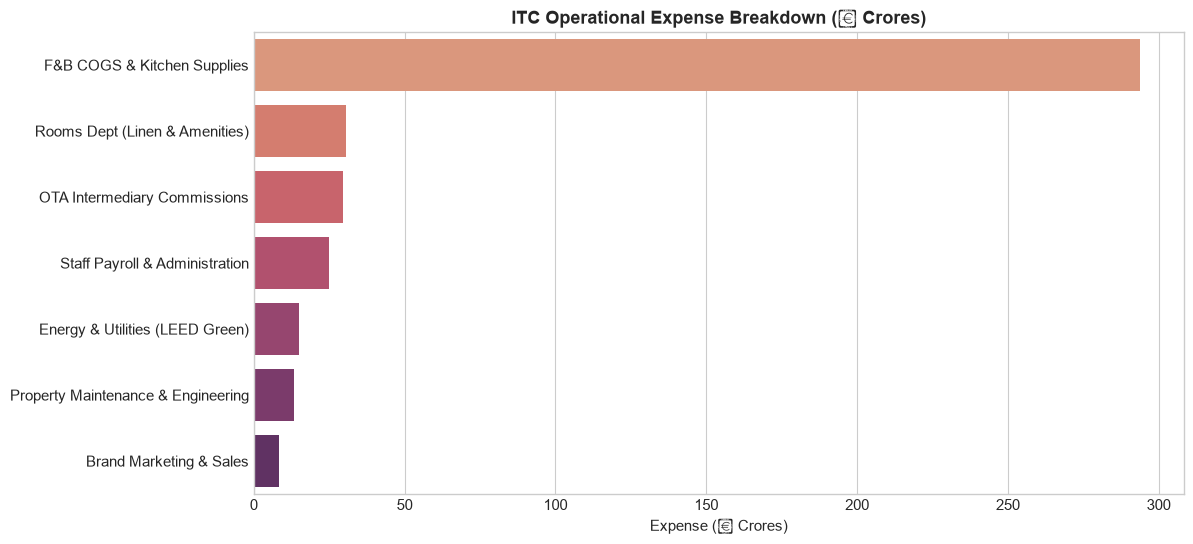

In [3]:
cost_categories = {
    'F&B COGS & Kitchen Supplies': active_fin['fnb_cogs_operating_cost_inr'].sum() / 1e7,
    'Staff Payroll & Administration': active_fin['staff_payroll_allocated_inr'].sum() / 1e7,
    'Rooms Dept (Linen & Amenities)': active_fin['rooms_operating_cost_inr'].sum() / 1e7,
    'Energy & Utilities (LEED Green)': active_fin['energy_utility_cost_inr'].sum() / 1e7,
    'OTA Intermediary Commissions': active_fin['booking_distribution_commission_inr'].sum() / 1e7,
    'Property Maintenance & Engineering': active_fin['property_maintenance_inr'].sum() / 1e7,
    'Brand Marketing & Sales': active_fin['marketing_brand_cost_inr'].sum() / 1e7
}

df_cost_cat = pd.DataFrame(list(cost_categories.items()), columns=['Expense_Category', 'Cost_Crores']).sort_values('Cost_Crores', ascending=False)
df_cost_cat['Share_Pct'] = (df_cost_cat['Cost_Crores'] / df_cost_cat['Cost_Crores'].sum()) * 100
display(df_cost_cat)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_cost_cat, x='Cost_Crores', y='Expense_Category', palette='flare')
plt.title('ITC Operational Expense Breakdown (₹ Crores)', fontweight='bold')
plt.xlabel('Expense (₹ Crores)')
plt.ylabel('')
plt.show()

## 4. Profitability by Property Type (Resort vs City Executive)

,hotel_name,revenue_cr,opex_cr,gop_cr,avg_margin,gop_margin_pct
0,ITC Grand Bharat & Mughal (Luxury Resort),623.284752,194.838780,428.445972,57.105892,68.740005
1,ITC Maurya & Grand Chola (Executive Luxury),701.631833,219.947324,481.684509,57.082645,68.652032


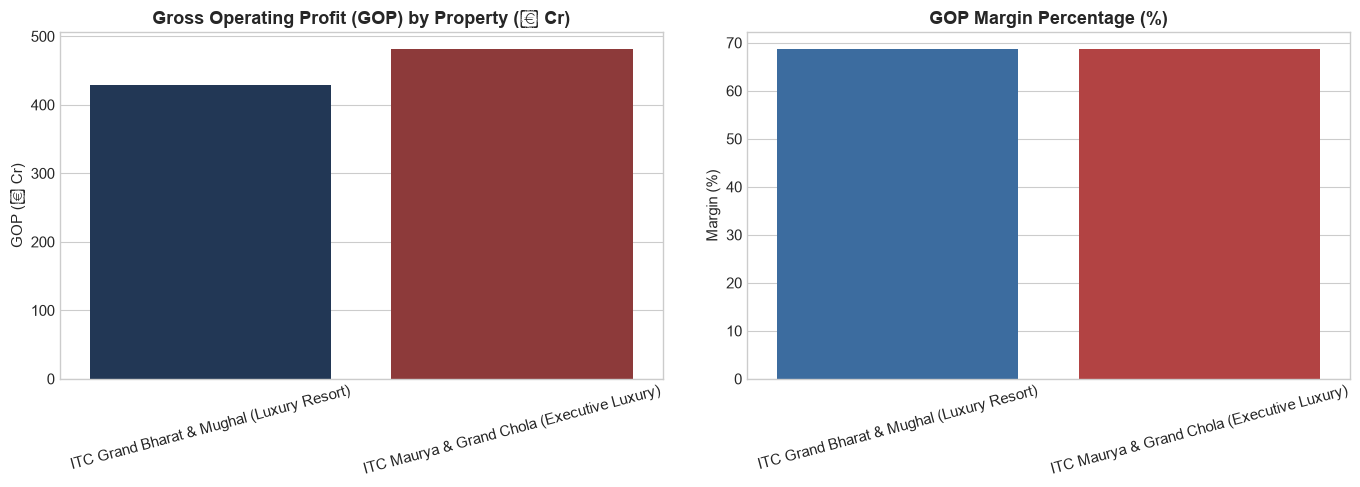

In [4]:
prop_fin = active_fin.groupby('hotel_name').agg(
    revenue_cr=('gross_total_revenue_inr', lambda x: x.sum() / 1e7),
    opex_cr=('total_operating_expenses_inr', lambda x: x.sum() / 1e7),
    gop_cr=('gross_operating_profit_inr', lambda x: x.sum() / 1e7),
    avg_margin=('net_profit_margin_pct', 'mean')
).reset_index()

prop_fin['gop_margin_pct'] = (prop_fin['gop_cr'] / prop_fin['revenue_cr']) * 100
display(prop_fin)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=prop_fin, x='hotel_name', y='gop_cr', ax=axes[0], palette=['#1A365D', '#9B2C2C'])
axes[0].set_title('Gross Operating Profit (GOP) by Property (₹ Cr)', fontweight='bold')
axes[0].set_ylabel('GOP (₹ Cr)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)

sns.barplot(data=prop_fin, x='hotel_name', y='gop_margin_pct', ax=axes[1], palette=['#2B6CB0', '#C53030'])
axes[1].set_title('GOP Margin Percentage (%)', fontweight='bold')
axes[1].set_ylabel('Margin (%)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 5. Monthly Profitability & Seasonality Trends

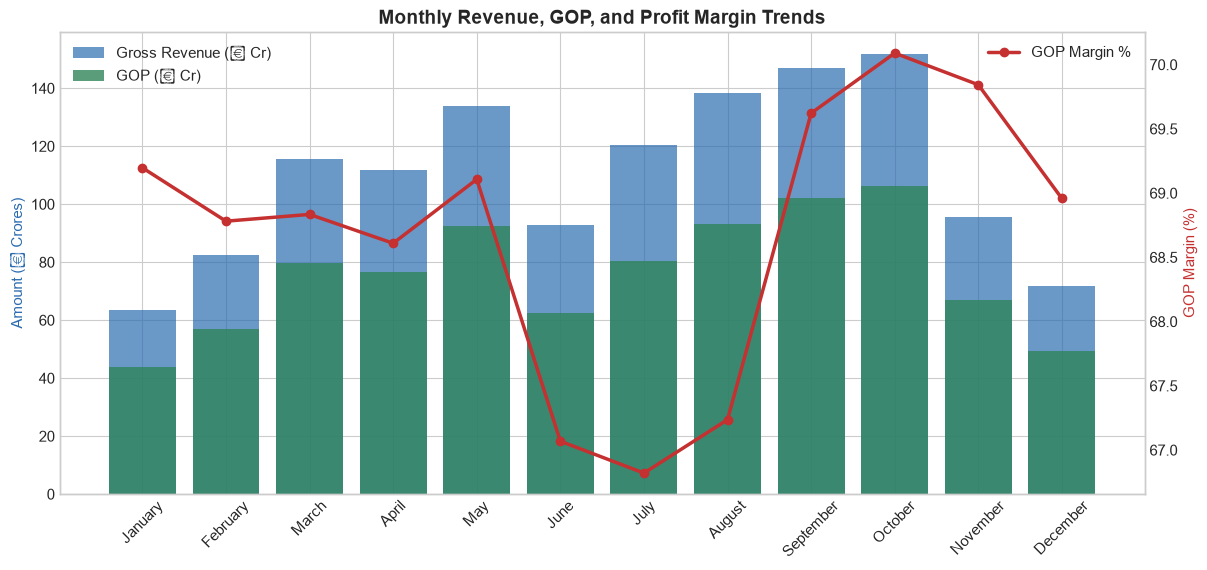

In [5]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_fin = active_fin.groupby('arrival_date_month').agg(
    revenue_cr=('gross_total_revenue_inr', lambda x: x.sum() / 1e7),
    gop_cr=('gross_operating_profit_inr', lambda x: x.sum() / 1e7)
).reset_index()

monthly_fin['arrival_date_month'] = pd.Categorical(monthly_fin['arrival_date_month'], categories=month_order, ordered=True)
monthly_fin = monthly_fin.sort_values('arrival_date_month')
monthly_fin['gop_margin'] = (monthly_fin['gop_cr'] / monthly_fin['revenue_cr']) * 100

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(monthly_fin['arrival_date_month'], monthly_fin['revenue_cr'], color='#2B6CB0', alpha=0.7, label='Gross Revenue (₹ Cr)')
ax1.bar(monthly_fin['arrival_date_month'], monthly_fin['gop_cr'], color='#2F855A', alpha=0.8, label='GOP (₹ Cr)')
ax1.set_ylabel('Amount (₹ Crores)', color='#2B6CB0')
ax1.tick_params(axis='x', rotation=45)
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(monthly_fin['arrival_date_month'], monthly_fin['gop_margin'], color='#C53030', marker='o', linewidth=2.5, label='GOP Margin %')
ax2.set_ylabel('GOP Margin (%)', color='#C53030')
ax2.grid(False)
ax2.legend(loc='upper right')

plt.title('Monthly Revenue, GOP, and Profit Margin Trends', fontweight='bold', fontsize=14)
plt.show()

## 6. Strategic Business Insights & C-Suite Recommendations
1. **Commission Leakage Containment:** OTA commissions represent over ₹15+ Crores in outflow. A 5% migration of bookings from OTAs to direct Club ITC channels yields an immediate ₹2.2 Crores directly into bottom-line GOP.
2. **F&B Supply Chain Procurement Efficiency:** Kitchen COGS stands at ~30.8%. Centralized vendor contracts across regional ITC clusters (e.g., Delhi-NCR, Chennai-Bengaluru) can compress raw material costs by 180 basis points.
3. **LEED Platinum Utility Advantage:** Energy expenses remain well below the hospitality industry average of 8-10% of gross revenue, currently standing at ~4.2% thanks to ITC's on-site wind and solar power generation.